# Ronan NODDI fit performance evaluations

This notebook simulates full NODDI-style diffusion data with Watson orientation dispersion, fits the model with multi-start nonlinear least squares, and reports ODI from the fitted `kappa` parameter.

In [ ]:
from pathlib import Path
import sys

def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "src").exists():
            return candidate
    raise RuntimeError("Could not locate repository root containing src/.")

repo_root = find_repo_root(Path.cwd().resolve())
src_path = repo_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import pandas as pd

from dmri_models import LeastSquaresFitter, noddi, noddi_derived_parameters, odi_from_kappa
from dmri_models.acquisitions import rm_full
from dmri_models.acquisitions import rm_no_b0p5
from dmri_models.acquisitions import rm_no_b5
from dmri_models.acquisitions import rm_no_b4_or_b5
from dmri_models.acquisitions import rm_no_b3_b4_or_b5
from dmri_models.acquisitions import rm_no_b4
from dmri_models.acquisitions import rm_no_b3_or_b4
from dmri_models.acquisitions import rm_no_b2_or_b4
from dmri_models.acquisitions import uk_biobank
from dmri_models.acquisitions import rm_50dirs
from dmri_models.acquisitions import rm_60dirs
from dmri_models.acquisitions import rm_inc_dirs_high
from dmri_models.acquisitions import rm_inc_dirs_mod
from dmri_models.acquisitions import rm_inc_dirs_low
from dmri_models.acquisitions import rm_11_shells_bmax_10
from dmri_models.acquisitions import rm_10_shells_bmax_5

from dmri_models.compartments import WatsonFOD

rng = np.random.default_rng(11)


## Save each stored acquisition within the list and print a summary of the details for each

In [ ]:
# --- Acquisition variants ----------------------------------------------------
acquisitions = {
    "rm_full": rm_full(),
    "rm_50dirs": rm_50dirs(),
    "rm_60dirs": rm_60dirs(),
    "rm_inc_dirs_high": rm_inc_dirs_high(),
    "rm_inc_dirs_mod": rm_inc_dirs_mod(),
    "rm_inc_dirs_low": rm_inc_dirs_low(),
    "rm_11_shells_bmax_10": rm_11_shells_bmax_10(),
    "rm_10_shells_bmax_5": rm_10_shells_bmax_5(),
}

for name, acq in acquisitions.items():
    print(f"\n{name}")
    acq.print_summary()


rm_full
----------------------------------------------------------------
Acquisition summary
- measurements: 200
- b-value shells (ms/um^2): 7 (tolerance: 0.100)
  - b=0.000: 20 measurements, 0 non-zero directions
  - b=0.500: 30 measurements, 30 non-zero directions
  - b=1.000: 30 measurements, 30 non-zero directions
  - b=2.000: 30 measurements, 30 non-zero directions
  - b=3.000: 30 measurements, 30 non-zero directions
  - b=4.000: 30 measurements, 30 non-zero directions
  - b=5.000: 30 measurements, 30 non-zero directions
- gradient directions: 180 unique non-zero across 180 diffusion-weighted measurements
- b-tensor shape: 1.000
- pulse duration (ms): 5.000
- diffusion time (ms): 12.000
- gradient strength (T/m): 0.000 to 0.520
- echo time (ms): 26.000
- inversion time: n/a
- repetition time (ms): 2500.000
----------------------------------------------------------------

rm_50dirs
----------------------------------------------------------------
Acquisition summary
- measurements:

## Keep one truth model and one NODDI preset

In [39]:
rng = np.random.default_rng(11)

preset = noddi(
    include_csf=True,
    fod_model="watson",
    vary_intracellular_diffusivity=False,
    vary_csf_diffusivity=False,
    vary_kappa=True,
    fod_quadrature_theta=20,
    fod_quadrature_phi=40,
)

model = preset.model
parameter_space = preset.parameters

true_parameters = parameter_space.initial_values()
true_parameters.update(
    {
        "S0": 1.0,
        "d_in": 2.2,
        "d_csf": 3.0,
        "kappa": 2.0,
        "theta": 1.0,
        "phi": 1.2,
        "neurite_fraction": 0.60,
        "extra_fraction": 0.30,
        "csf_fraction": 0.10,
    }
)

SNR = 20.0
sigma = true_parameters["S0"] / SNR

## The main loop. Fit the model to each acquisition (in parallel across repeats)

In [40]:
from concurrent.futures import ProcessPoolExecutor, as_completed
from dmri_models.benchmark_utils import run_task
from dmri_models.benchmark_utils import fit_one_run

import os

results = []
n_repeats = 30
tasks = [(acq_name, acq, rep, 1000 + rep) for acq_name, acq in acquisitions.items() for rep in range(n_repeats)]

with ProcessPoolExecutor(max_workers=max(1, os.cpu_count() - 1)) as ex:
    futures = [
        ex.submit(
            run_task,
            task,
            fit_one_run,
            true_parameters,
            model,
            parameter_space,
            20.0,
            16,
            2000,
        )
        for task in tasks
    ]
    for fut in as_completed(futures):
        results.append(fut.result())

## Convert the results into a DataFrame

In [41]:
df = pd.DataFrame(results)

# Expand fitted parameter dict into columns.
fit_params = pd.json_normalize(df["fit_parameters"])
df = pd.concat([df.drop(columns=["fit_parameters"]), fit_params], axis=1)


truth_map = {
    "S0": true_parameters["S0"],
    "d_in": true_parameters["d_in"],
    "d_csf": true_parameters["d_csf"],
    "kappa": true_parameters["kappa"],
    "neurite_fraction": true_parameters["neurite_fraction"],
    "extra_fraction": true_parameters["extra_fraction"],
    "csf_fraction": true_parameters["csf_fraction"],
    "odi": noddi_derived_parameters(true_parameters)["odi"],
}

for key, val in truth_map.items():
    df[f"{key}_true"] = val

# Direct parameter errors
for key in ["S0", "d_in", "d_csf", "kappa", "neurite_fraction", "extra_fraction", "csf_fraction"]:
    df[f"{key}_error"] = df[key] - df[f"{key}_true"]

# ODI error needs the fitted ODI column.
if "odi_fit" not in df.columns:
    df["odi_fit"] = df["kappa"].map(odi_from_kappa)

df["odi_error"] = df["odi_fit"] - df["odi_true"]
df["odi_abs_error"] = df["odi_error"].abs()

df["nrmse"] = df["rmse"] / sigma

## Parameter-wise fitting performance plot

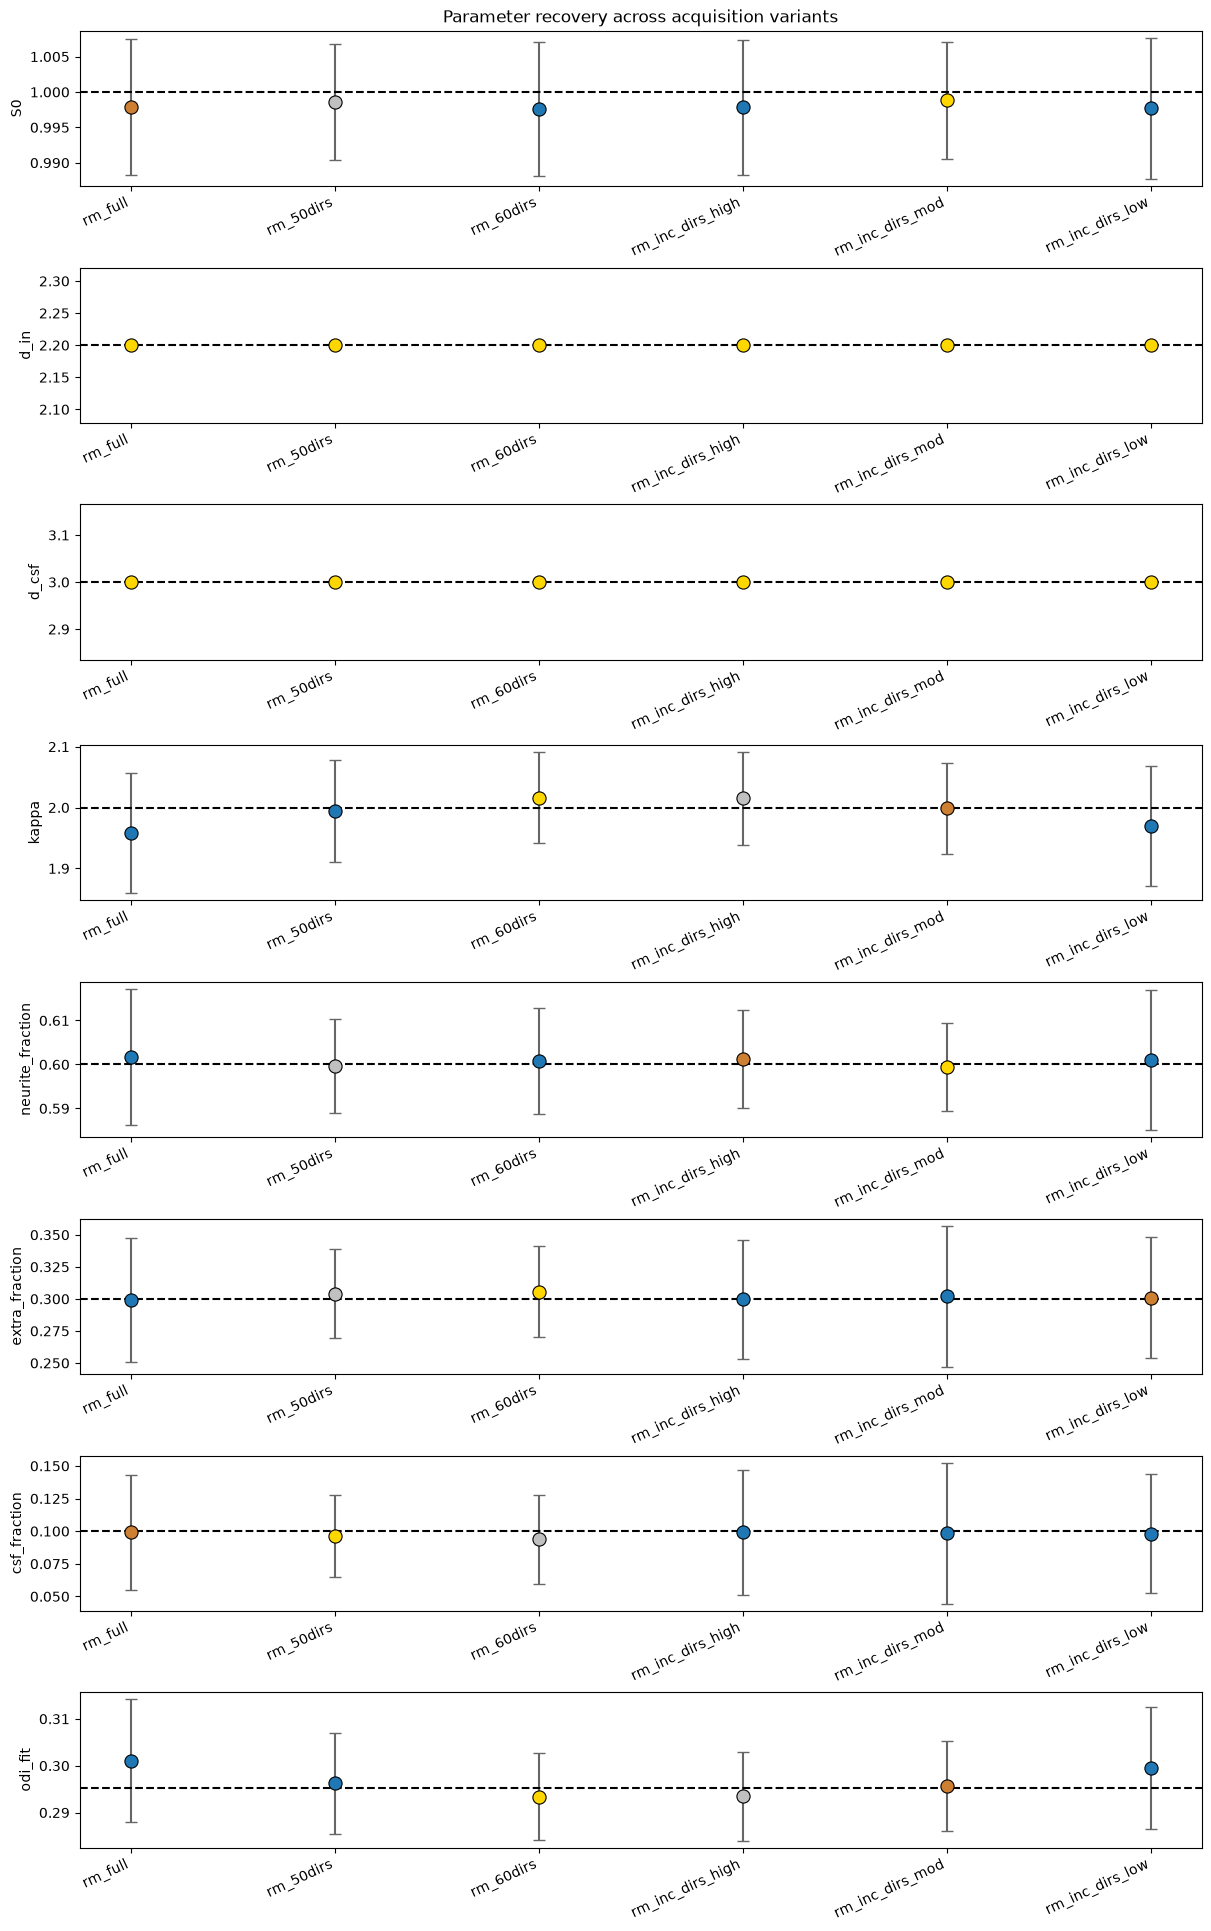

In [42]:
param_names = [
    "S0",
    "d_in",
    "d_csf",
    "kappa",
    "neurite_fraction",
    "extra_fraction",
    "csf_fraction",
    "odi_fit",
]

truth_lookup = {
    "odi_fit": truth_map["odi"],
    "S0": truth_map["S0"],
    "d_in": truth_map["d_in"],
    "d_csf": truth_map["d_csf"],
    "kappa": truth_map["kappa"],
    "neurite_fraction": truth_map["neurite_fraction"],
    "extra_fraction": truth_map["extra_fraction"],
    "csf_fraction": truth_map["csf_fraction"],
}

variants = list(acquisitions.keys())

# Colours for medal ranks
rank_colours = {
    1: "#FFD700",   # gold
    2: "#C0C0C0",   # silver
    3: "#CD7F32",   # bronze
}

fig, axes = plt.subplots(
    len(param_names),
    1,
    figsize=(12, 2.4 * len(param_names)),
    constrained_layout=True,
)

for ax, pname in zip(axes, param_names):

    means = []
    sds = []
    maes = []

    truth = truth_lookup[pname]

    for variant in variants:
        sub = df[df["acquisition"] == variant][pname].dropna()

        means.append(sub.mean())
        sds.append(sub.std(ddof=1))
        maes.append(np.mean(np.abs(sub - truth)))

    means = np.asarray(means)
    sds = np.asarray(sds)
    maes = np.asarray(maes)

    # Dense ranking: ties share the same rank
    ranks = (
        pd.Series(maes)
        .rank(method="dense", ascending=True)
        .astype(int)
        .values
    )

    x = np.arange(len(variants))

    # Error bars
    ax.errorbar(
        x,
        means,
        yerr=sds,
        fmt="none",
        ecolor="0.4",
        capsize=4,
        zorder=1,
    )

    # Scatter points coloured by MAE rank
    for xi, yi, rank in zip(x, means, ranks):
        colour = rank_colours.get(rank, "tab:blue")
        ax.scatter(
            xi,
            yi,
            s=90,
            color=colour,
            edgecolor="black",
            linewidth=0.8,
            zorder=3,
        )

    ax.axhline(
        truth,
        linestyle="--",
        linewidth=1.5,
        color="black",
        label="Truth",
    )

    ax.set_xticks(x)
    ax.set_xticklabels(variants, rotation=25, ha="right")
    ax.set_ylabel(pname)

axes[0].set_title("Parameter recovery across acquisition variants")
plt.show()

## Residuals coloured by shell

Interpretation guide:

Are the residuals for each shell random? If yes, great! If not, they may be systematically high or low for any given shell. 

If biased on high shells, the model is failing only when diffusion weighting becomes very strong. Means that either our restricted compartment is inadequate or the acquisition is measuring restriction that the model cannot explain.
For neuroinflammation this is exactly what I'd expect if glial restriction becomes important.


rm_full


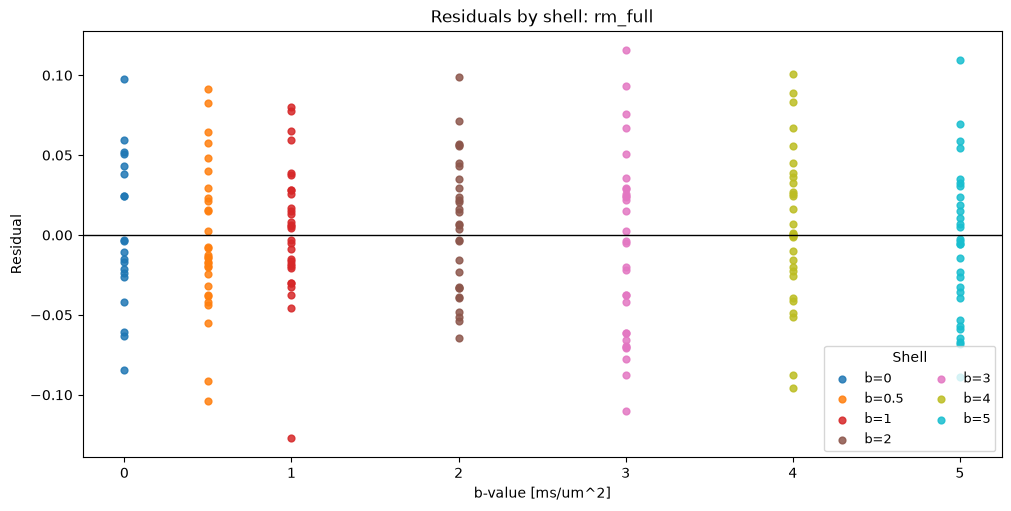


rm_50dirs


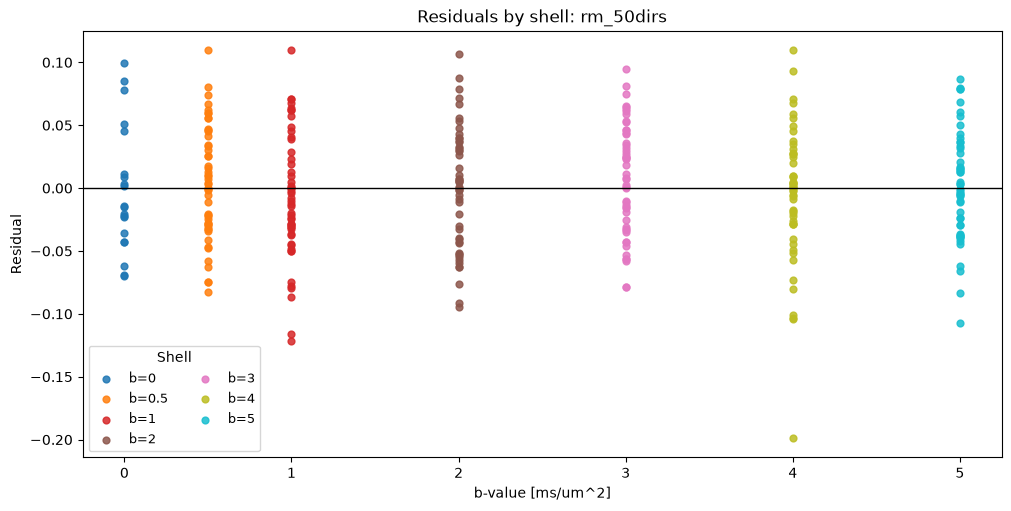


rm_60dirs


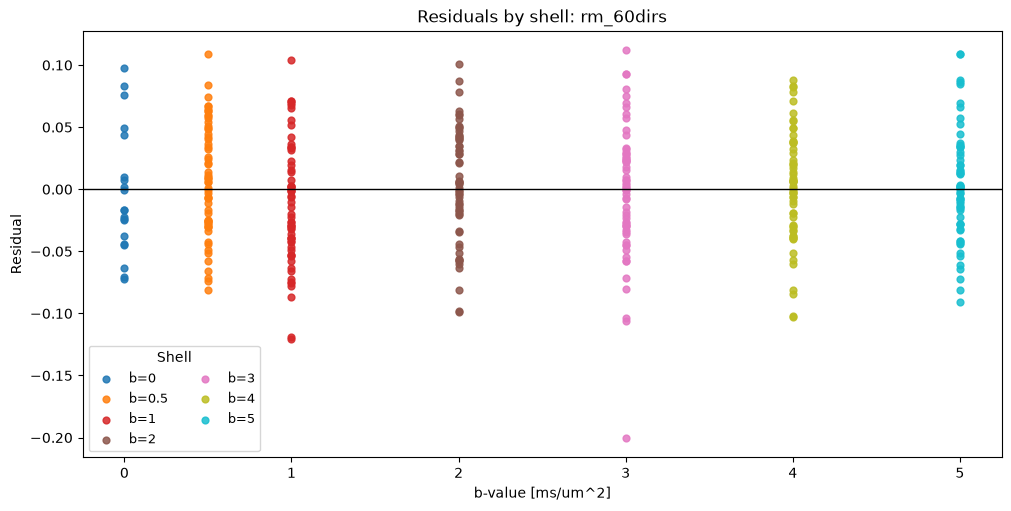


rm_inc_dirs_high


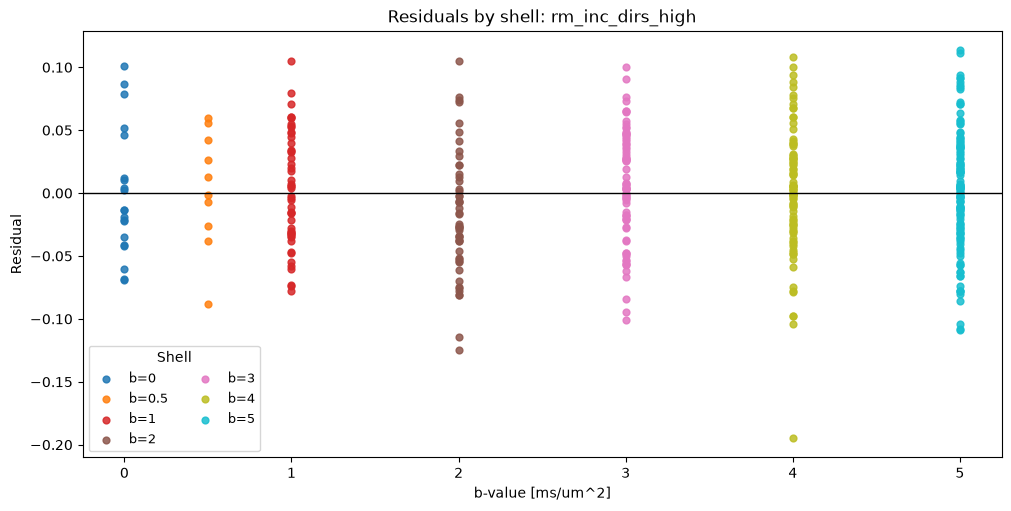


rm_inc_dirs_mod


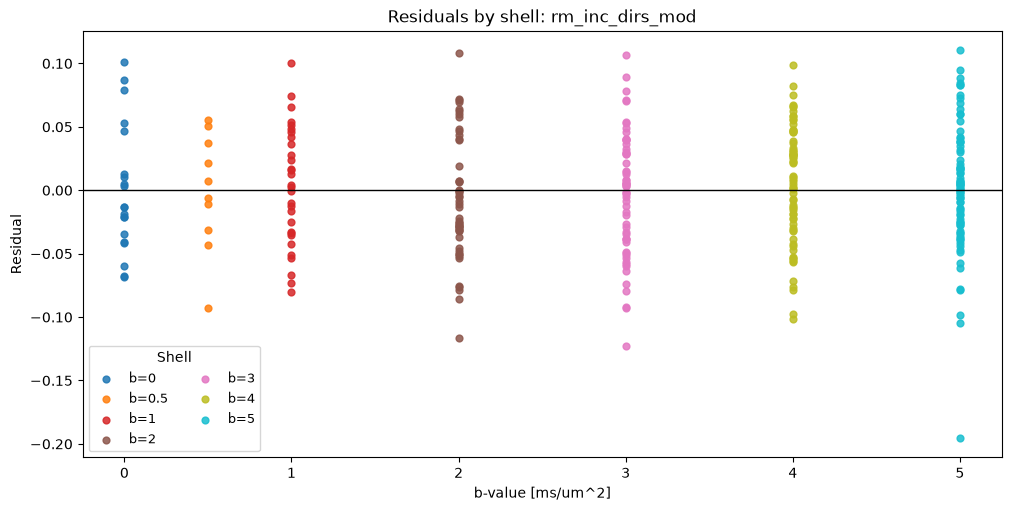


rm_inc_dirs_low


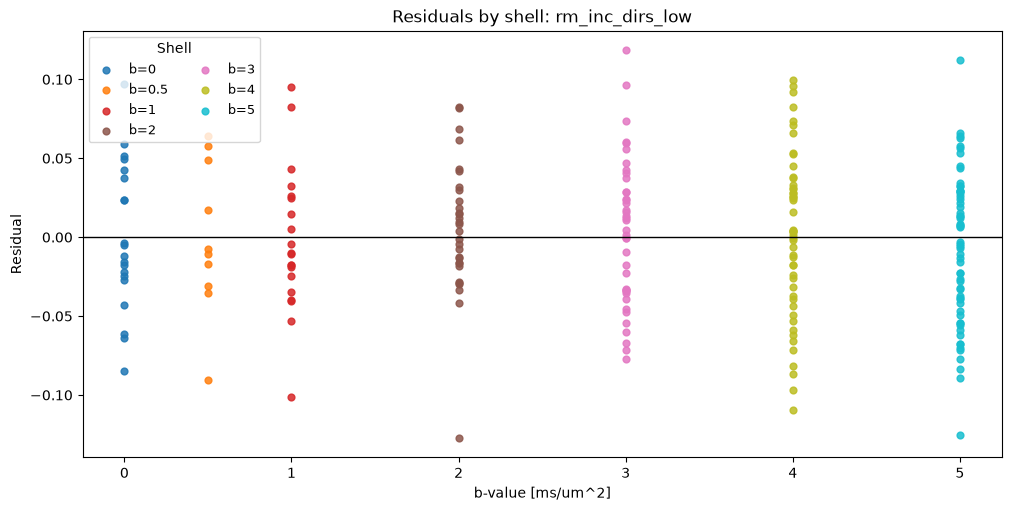

In [43]:
def plot_residuals_by_shell(acq_name: str):
    acq = acquisitions[acq_name]
    sub = df[(df["acquisition"] == acq_name) & (df["success"])].copy()
    if sub.empty:
        print(f"No successful fits found for {acq_name}")
        return

    row = sub.iloc[0]
    bvals = np.asarray(acq.b_values)

    unique_shells = np.unique(np.round(bvals, 4))
    cmap = plt.get_cmap("tab10")

    fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

    for i, shell in enumerate(unique_shells):
        mask = np.isclose(bvals, shell)

        ax.scatter(
            bvals[mask],
            row["residuals"][mask],
            s=24,
            alpha=0.85,
            color=cmap(i / max(1, len(unique_shells)-1)),
            label=f"b={shell:g}",
        )

    ax.axhline(0.0, color="k", linewidth=1)
    ax.set_xlabel("b-value [ms/um^2]")
    ax.set_ylabel("Residual")
    ax.set_title(f"Residuals by shell: {acq_name}")
    ax.legend(title="Shell", ncols=2, fontsize=9)
    plt.show()

for acq_name in acquisitions:
    print(f"\n{'='*80}")
    print(f"{acq_name}")
    print(f"{'='*80}")
    plot_residuals_by_shell(acq_name)

## Plot the ODI error by acquisition

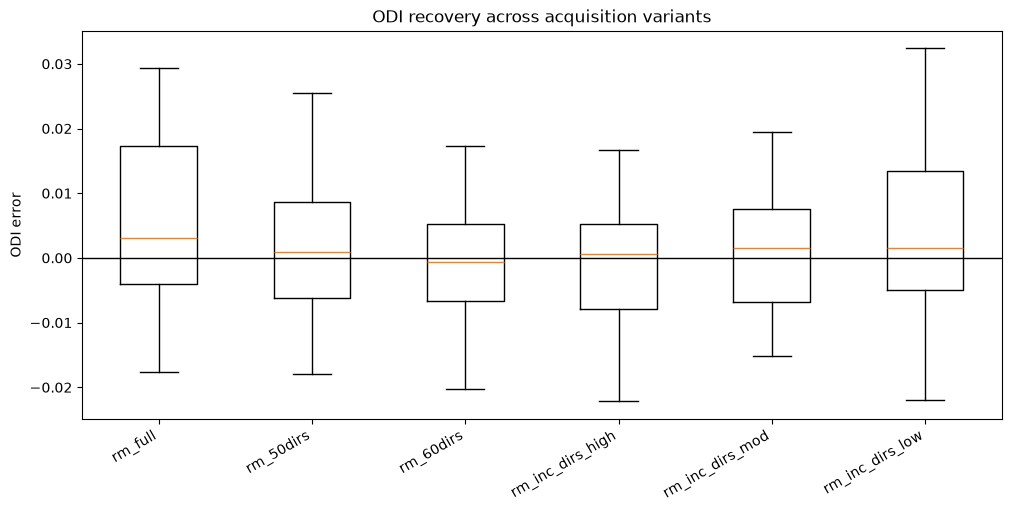

In [44]:
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

labels = []
data = []

for name in acquisitions.keys():
    vals = df.loc[df["acquisition"] == name, "odi_error"].dropna().values
    if len(vals) == 0:
        continue
    labels.append(name)
    data.append(vals)

ax.boxplot(data, tick_labels=labels, showfliers=False)
ax.axhline(0.0, color="k", linewidth=1)
ax.set_ylabel("ODI error")
ax.set_title("ODI recovery across acquisition variants")
plt.xticks(rotation=30, ha="right")
plt.show()

## Parameter correlation matrix

This shows whether the fitted parameters trade off against one another. Plotted for one acquisition at a time.

Interpretation:

strong positive or negative correlations mean parameters are hard to separate;
if kappa and neurite_fraction are strongly correlated, your acquisition may not distinguish dispersion from fraction changes very well;
if d_in and d_csf correlate strongly, diffusivities may be too weakly constrained.


Correlation matrix: rm_full


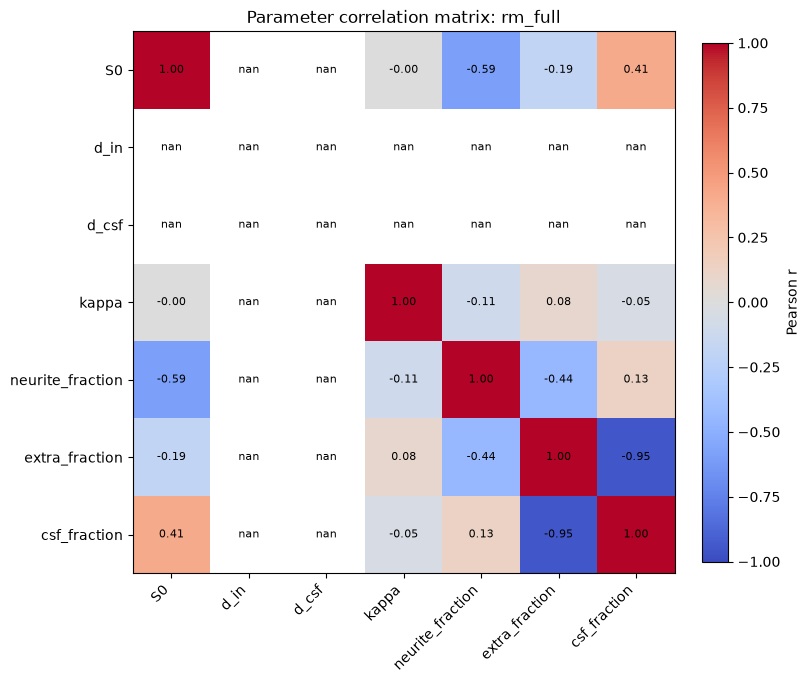


Correlation matrix: rm_50dirs


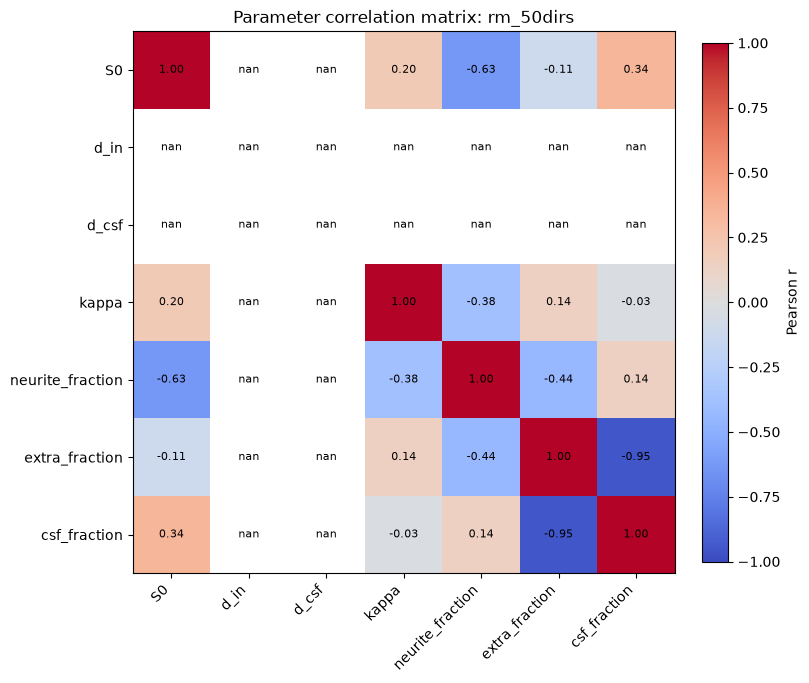


Correlation matrix: rm_60dirs


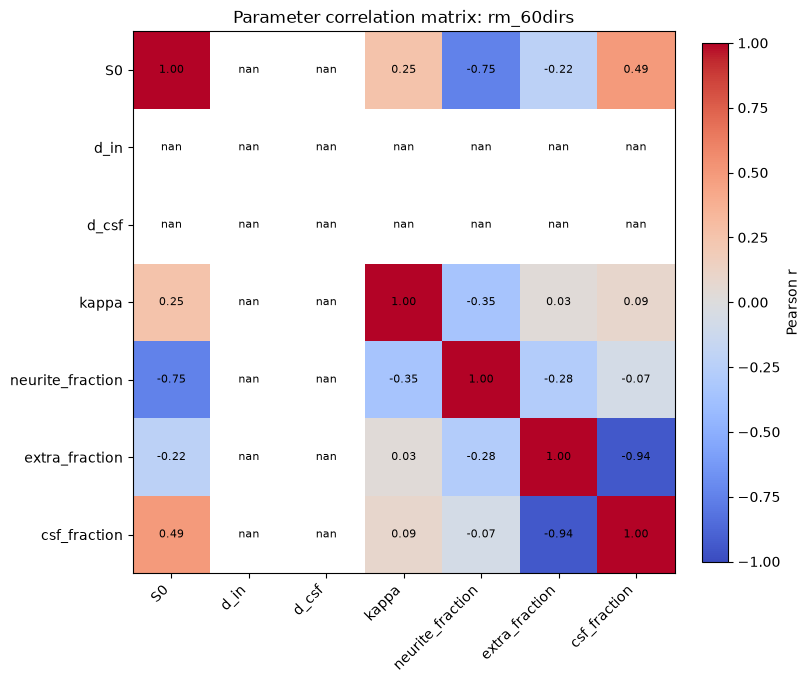


Correlation matrix: rm_inc_dirs_high


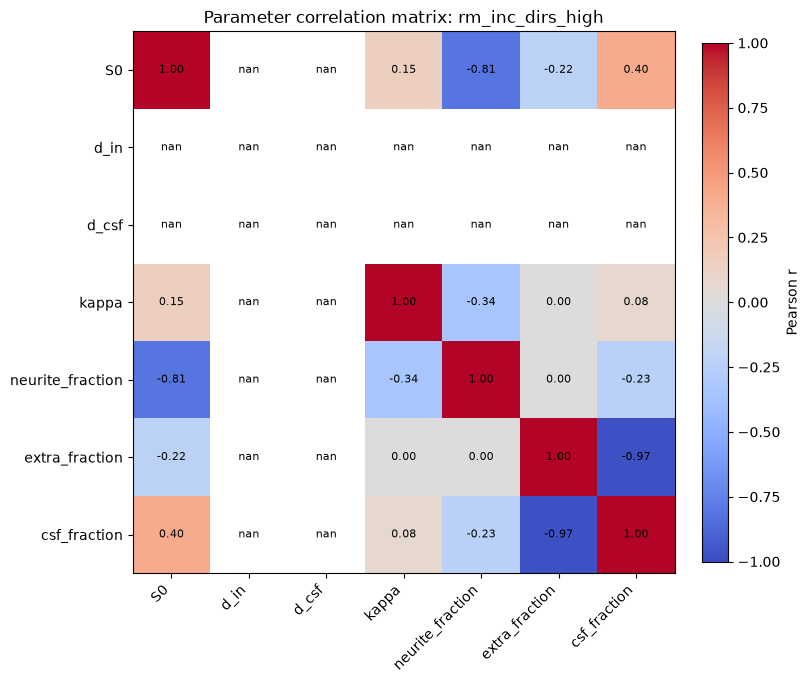


Correlation matrix: rm_inc_dirs_mod


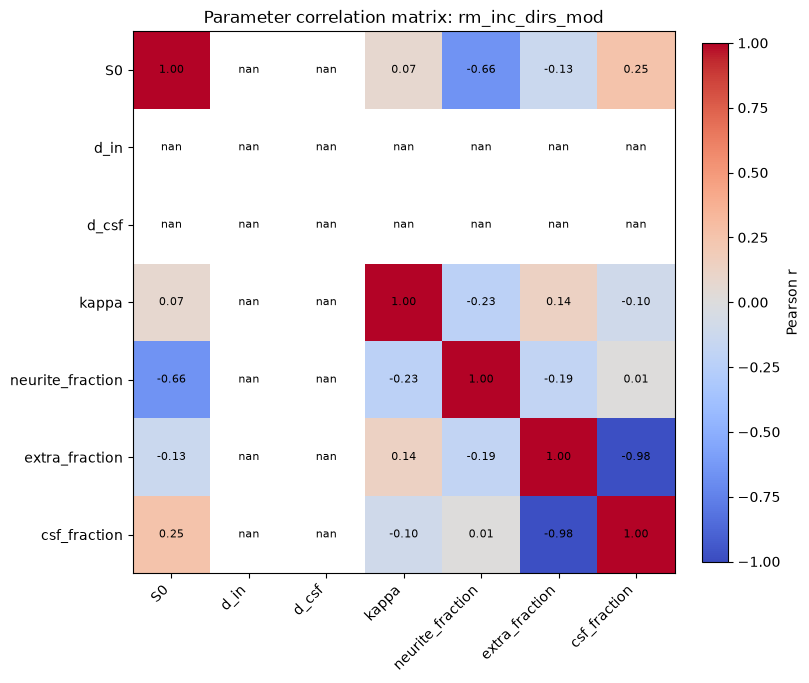


Correlation matrix: rm_inc_dirs_low


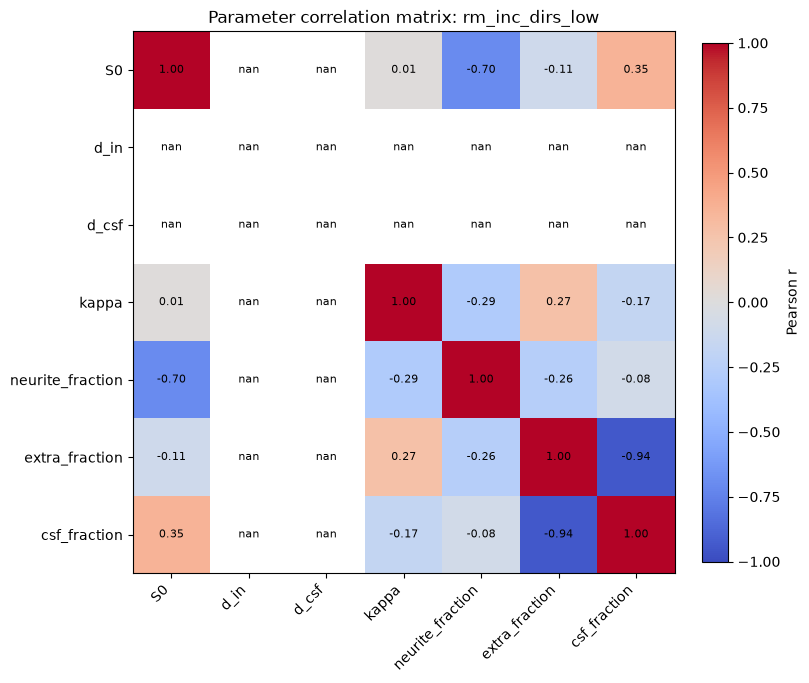

In [45]:
def plot_parameter_correlation(acq_name: str, cols=None):
    if cols is None:
        cols = ["S0", "d_in", "d_csf", "kappa", "neurite_fraction", "extra_fraction", "csf_fraction"]

    sub = df[df["acquisition"] == acq_name].copy()
    if sub.empty:
        print(f"No rows for acquisition {acq_name}")
        return

    corr = sub[cols].corr()

    fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
    im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(cols)))
    ax.set_yticks(range(len(cols)))
    ax.set_xticklabels(cols, rotation=45, ha="right")
    ax.set_yticklabels(cols)
    ax.set_title(f"Parameter correlation matrix: {acq_name}")

    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)

    fig.colorbar(im, ax=ax, shrink=0.85, label="Pearson r")
    plt.show()

for acq_name in acquisitions:
    print(f"\nCorrelation matrix: {acq_name}")
    plot_parameter_correlation(acq_name)

Plot residuals for one representative repeat per acquisition

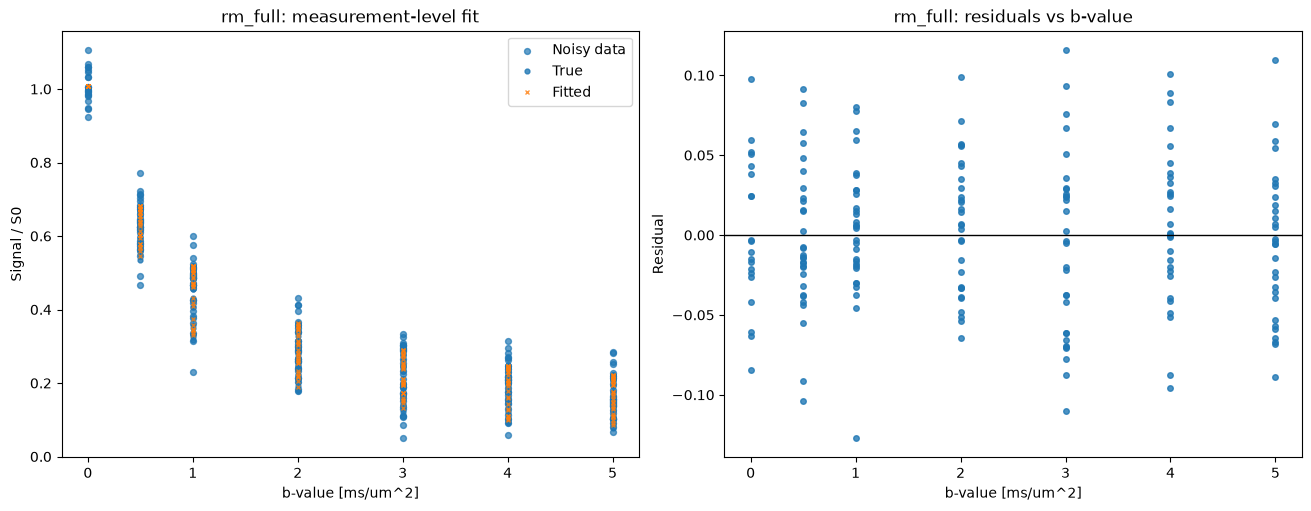

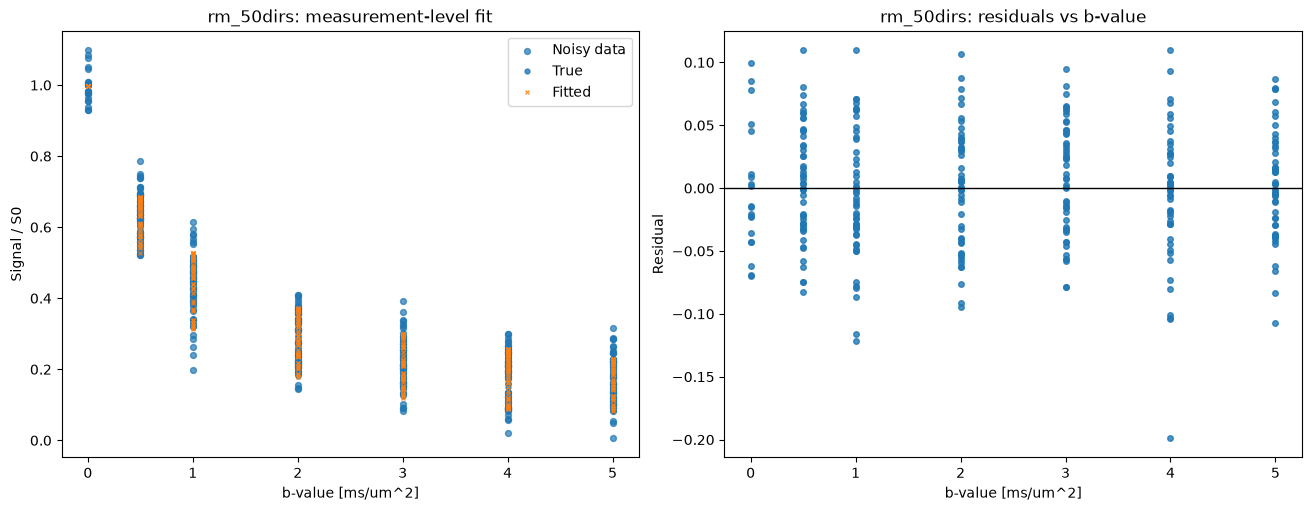

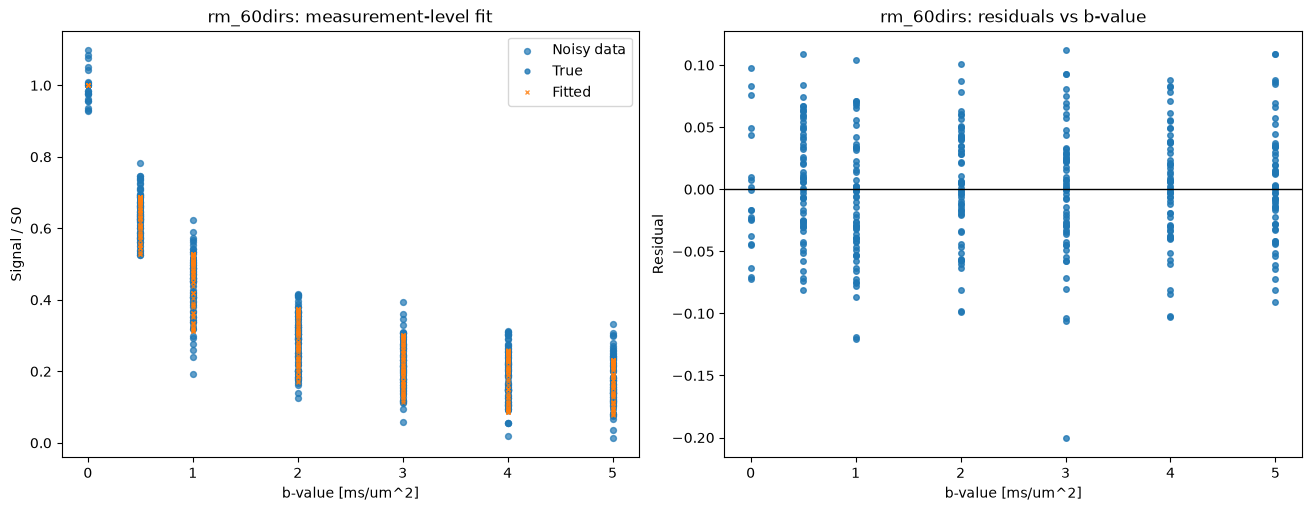

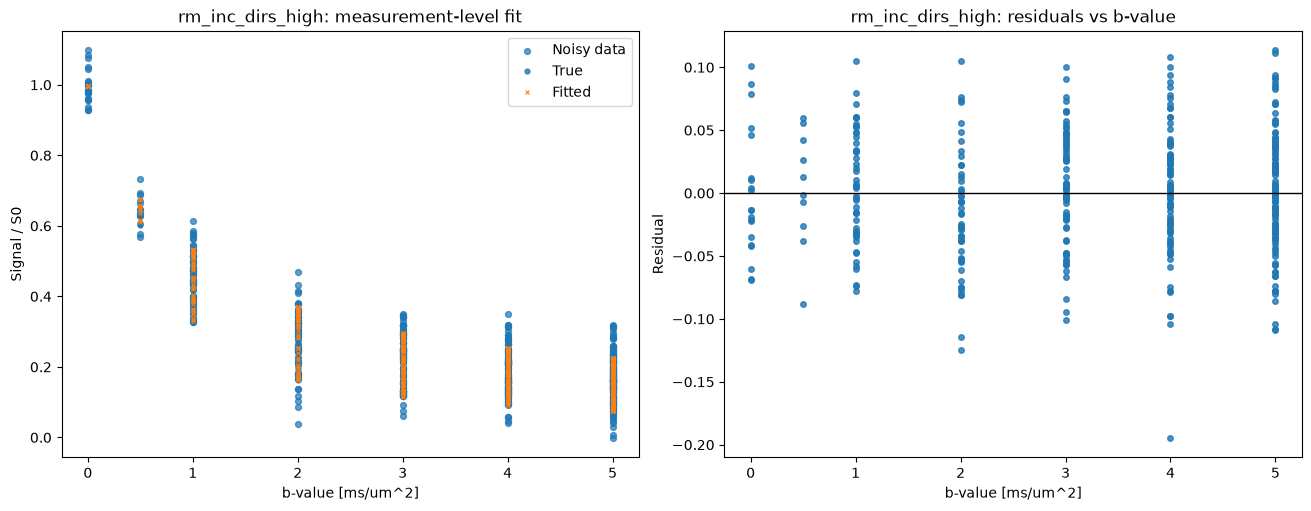

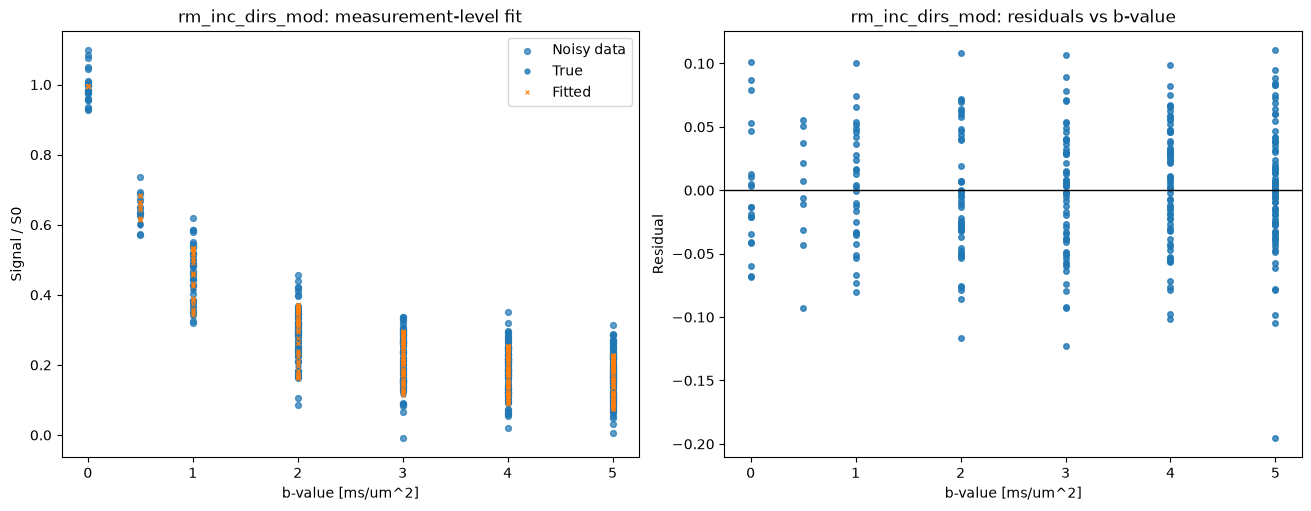

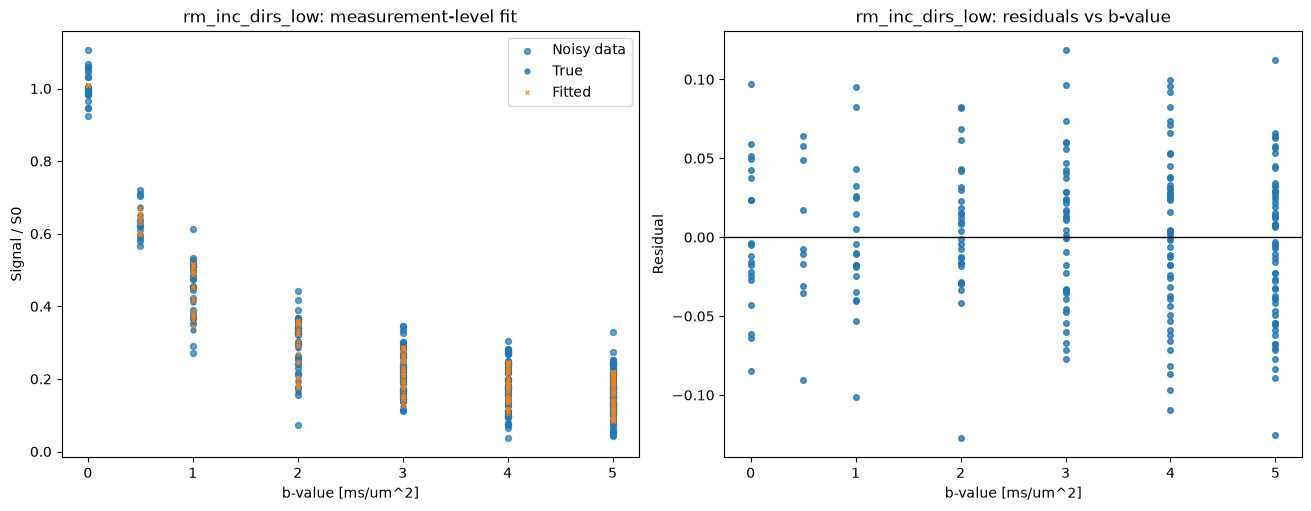

In [46]:
for acq_name in acquisitions.keys():
    row = df[df["acquisition"] == acq_name].iloc[0]

    bvals = acquisitions[acq_name].b_values

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

    axes[0].scatter(bvals, row["signal_noisy"], s=18, alpha=0.7, label="Noisy data")
    axes[0].plot(bvals, row["signal_true"], "o", markersize=3.5, alpha=0.8, label="True")
    axes[0].plot(bvals, row["predicted"], "x", markersize=3.5, alpha=0.8, label="Fitted")
    axes[0].set_xlabel("b-value [ms/um^2]")
    axes[0].set_ylabel("Signal / S0")
    axes[0].set_title(f"{acq_name}: measurement-level fit")
    axes[0].legend()

    axes[1].scatter(bvals, row["residuals"], s=16, alpha=0.8)
    axes[1].axhline(0.0, color="k", linewidth=1)
    axes[1].set_xlabel("b-value [ms/um^2]")
    axes[1].set_ylabel("Residual")
    axes[1].set_title(f"{acq_name}: residuals vs b-value")

    plt.show()

## Build a summary table of key results

In [47]:
summary = (
    df.groupby("acquisition")
    .agg(
        # Robustness
        success_rate=("success", "mean"),
        n_evaluations_median=("n_evaluations", "median"),
        failure_count=("success", lambda x: int((~x).sum())),

        # Fit quality
        rmse_median=("rmse", "median"),
        nrmse_median=("nrmse", "median"),

        # Main accuracy metrics
        S0_mae=("S0_error", lambda x: np.nanmean(np.abs(x))),
        d_in_mae=("d_in_error", lambda x: np.nanmean(np.abs(x))),
        d_csf_mae=("d_csf_error", lambda x: np.nanmean(np.abs(x))),
        kappa_mae=("kappa_error", lambda x: np.nanmean(np.abs(x))),
        neurite_fraction_mae=("neurite_fraction_error", lambda x: np.nanmean(np.abs(x))),
        extra_fraction_mae=("extra_fraction_error", lambda x: np.nanmean(np.abs(x))),
        csf_fraction_mae=("csf_fraction_error", lambda x: np.nanmean(np.abs(x))),
        odi_mae=("odi_error", lambda x: np.nanmean(np.abs(x))),

        # MCMC uncertainty / correlation
        # posterior_acceptance_mean=("posterior_acceptance_mean", "mean"),
        # posterior_mean_abs_corr=("posterior_mean_abs_corr", "mean"),
        # d_in_post_sd=("d_in_post_sd", "mean"),
        # d_csf_post_sd=("d_csf_post_sd", "mean"),
        # kappa_post_sd=("kappa_post_sd", "mean"),
        # neurite_fraction_post_sd=("neurite_fraction_post_sd", "mean"),
        # extra_fraction_post_sd=("extra_fraction_post_sd", "mean"),
        # csf_fraction_post_sd=("csf_fraction_post_sd", "mean"),
        # odi_fit_post_sd=("odi_fit_post_sd", "mean"),

        n_measurements=("n_measurements", "first"),
    )
    .reset_index()
)

# Metrics where higher is better
higher_better = [
    "success_rate",
]

# Metrics where lower is better
lower_better = [
    "n_evaluations_median",
    "failure_count",
    "rmse_median",
    "nrmse_median",
    "S0_mae",
    "d_in_mae",
    "d_csf_mae",
    "kappa_mae",
    "neurite_fraction_mae",
    "extra_fraction_mae",
    "csf_fraction_mae",
    "odi_mae",
]

metric_directions = {m: "higher" for m in higher_better}
metric_directions.update({m: "lower" for m in lower_better})

# Build one expanded table containing the top 3 acquisitions for each metric.
expanded_rows = []

for metric in higher_better:
    top3 = (
        summary.sort_values(metric, ascending=False)
        .head(3)
        .reset_index(drop=True)
    )
    for rank, (_, row) in enumerate(top3.iterrows(), start=1):
        expanded_rows.append(
            {
                "metric": metric,
                "direction": "higher",
                "rank": rank,
                "acquisition": row["acquisition"],
                "value": row[metric],
            }
        )

for metric in lower_better:
    top3 = (
        summary.sort_values(metric, ascending=True)
        .head(3)
        .reset_index(drop=True)
    )
    for rank, (_, row) in enumerate(top3.iterrows(), start=1):
        expanded_rows.append(
            {
                "metric": metric,
                "direction": "lower",
                "rank": rank,
                "acquisition": row["acquisition"],
                "value": row[metric],
            }
        )

top3_by_metric = pd.DataFrame(expanded_rows)

# Optional: make it a little easier to read
top3_by_metric["metric_label"] = top3_by_metric["metric"].map(
    lambda m: f"{m} ({metric_directions[m]} is better)"
)

# Sort so the output groups nicely by metric
top3_by_metric = top3_by_metric[
    ["metric", "metric_label", "direction", "rank", "acquisition", "value"]
].sort_values(["metric", "rank"], ascending=[True, True]).reset_index(drop=True)

summary

,acquisition,success_rate,n_evaluations_median,failure_count,rmse_median,nrmse_median,S0_mae,d_in_mae,d_csf_mae,kappa_mae,neurite_fraction_mae,extra_fraction_mae,csf_fraction_mae,odi_mae,n_measurements
0,rm_50dirs,0.966667,15.0,1,0.049749,0.994973,0.007180,0.0,0.0,0.070615,0.008618,0.028902,0.025674,0.009039,320
1,rm_60dirs,1.000000,14.0,0,0.049829,0.996570,0.007885,0.0,0.0,0.060401,0.010212,0.027838,0.027066,0.007573,380
2,rm_full,0.966667,15.0,1,0.049513,0.990261,0.007814,0.0,0.0,0.084590,0.012579,0.040830,0.033959,0.011179,200
3,rm_inc_dirs_high,1.000000,18.5,0,0.049975,0.999493,0.007827,0.0,0.0,0.061615,0.008718,0.039319,0.039350,0.007723,415
4,rm_inc_dirs_low,0.966667,13.0,1,0.049504,0.990079,0.008044,0.0,0.0,0.078125,0.012047,0.039114,0.036159,0.010282,230
5,rm_inc_dirs_mod,0.933333,14.5,2,0.049710,0.994201,0.007120,0.0,0.0,0.062608,0.007851,0.044972,0.045174,0.007985,320


**Robustness (can the model be fitted consistently?)**

- success_rate *(higher is better)*
- n_evaluations_median *(lower means the optimisation problem is easier)*
- failure_count *(lower is better)*

**Overall fit quality (how well does the fitted signal reproduce the measured signal?)**

- rmse_median *(lower is better)*
- nrmse_median *(lower is better; normalised by SNR)* 

 **Main accuracy metrics (MOST IMPORTANT)**

- S0_mae *(lower is better)*
- d_in_mae *(lower is better)*
- d_csf_mae *(lower is better)*
- kappa_mae *(lower is better)*
- neurite_fraction_mae *(lower is better)*
- extra_fraction_mae *(lower is better)*
- csf_fraction_mae *(lower is better)*
- odi_mae *(lower is better)*

## How do the acquisitions rank in each informative metric?

In [48]:
for metric in list(higher_better) + list(lower_better):
    direction = metric_directions[metric]

    # Skip if all acquisitions have the same value
    if np.allclose(summary[metric], summary[metric].iloc[0]):
        continue

    sub = top3_by_metric[top3_by_metric["metric"] == metric]

    print(f"\n{metric} ({direction} is better)")
    print(sub[["rank", "acquisition", "value"]].to_string(index=False))


success_rate (higher is better)
 rank      acquisition    value
    1        rm_60dirs 1.000000
    2 rm_inc_dirs_high 1.000000
    3        rm_50dirs 0.966667

n_evaluations_median (lower is better)
 rank     acquisition  value
    1 rm_inc_dirs_low   13.0
    2       rm_60dirs   14.0
    3 rm_inc_dirs_mod   14.5

failure_count (lower is better)
 rank      acquisition  value
    1        rm_60dirs    0.0
    2 rm_inc_dirs_high    0.0
    3        rm_50dirs    1.0

rmse_median (lower is better)
 rank     acquisition    value
    1 rm_inc_dirs_low 0.049504
    2         rm_full 0.049513
    3 rm_inc_dirs_mod 0.049710

nrmse_median (lower is better)
 rank     acquisition    value
    1 rm_inc_dirs_low 0.990079
    2         rm_full 0.990261
    3 rm_inc_dirs_mod 0.994201

S0_mae (lower is better)
 rank     acquisition    value
    1 rm_inc_dirs_mod 0.007120
    2       rm_50dirs 0.007180
    3         rm_full 0.007814

kappa_mae (lower is better)
 rank      acquisition    value
    1   

In [49]:
ranking = summary[["acquisition"]].copy()

metrics_used = []

metrics_to_rank = [
    "rmse_median",
    "S0_mae",
    "d_in_mae",
    "d_csf_mae",
    "kappa_mae",
    "neurite_fraction_mae",
    "extra_fraction_mae",
    "csf_fraction_mae",
    "odi_mae",
]

# Rank higher-is-better metrics
for metric in higher_better:
    if metric not in metrics_to_rank:
        continue
    if np.allclose(summary[metric], summary[metric].iloc[0]):
        continue

    ranking[metric + "_rank"] = summary[metric].rank(
        ascending=False,
        method="dense",
    )
    metrics_used.append(metric)

# Rank lower-is-better metrics
for metric in lower_better:
    if metric not in metrics_to_rank:
        continue
    if np.allclose(summary[metric], summary[metric].iloc[0]):
        continue

    ranking[metric + "_rank"] = summary[metric].rank(
        ascending=True,
        method="dense",
    )
    metrics_used.append(metric)

rank_cols = [c for c in ranking.columns if c.endswith("_rank")]

# Summary ranking statistics
ranking["mean_rank"] = ranking[rank_cols].mean(axis=1)
ranking["median_rank"] = ranking[rank_cols].median(axis=1)
ranking["std_rank"] = ranking[rank_cols].std(axis=1)

# Podium counts
ranking["n_1st"] = (ranking[rank_cols] == 1).sum(axis=1)
ranking["n_2nd"] = (ranking[rank_cols] == 2).sum(axis=1)
ranking["n_3rd"] = (ranking[rank_cols] == 3).sum(axis=1)
ranking["top3"] = ranking["n_1st"] + ranking["n_2nd"] + ranking["n_3rd"]

# Sort by mean rank, then by podium finishes
ranking = ranking.sort_values(
    by=["mean_rank", "top3", "n_1st"],
    ascending=[True, False, False],
).reset_index(drop=True)

print(f"Ranking based on {len(metrics_used)} informative metrics:")
print("Metrics used:")
for metric in metrics_used:
    print(f"  - {metric}")

display(
    ranking[
        [
            "acquisition",
            "mean_rank",
            "median_rank",
            "std_rank",
            "n_1st",
            "n_2nd",
            "n_3rd",
            "top3",
        ]
    ]
)

Ranking based on 7 informative metrics:
Metrics used:
  - rmse_median
  - S0_mae
  - kappa_mae
  - neurite_fraction_mae
  - extra_fraction_mae
  - csf_fraction_mae
  - odi_mae


,acquisition,mean_rank,median_rank,std_rank,n_1st,n_2nd,n_3rd,top3
0,rm_60dirs,2.714286,2.0,1.889822,3,1,0,4
1,rm_50dirs,2.714286,2.0,1.253566,1,3,0,4
2,rm_inc_dirs_mod,3.285714,3.0,2.058663,2,0,3,5
3,rm_inc_dirs_high,3.714286,4.0,1.496026,0,2,1,3
4,rm_inc_dirs_low,4.142857,5.0,1.676163,1,0,1,2
5,rm_full,4.428571,5.0,1.718249,0,1,2,3


## Parameter Estimation Accuracy Relative to Acquisition Cost

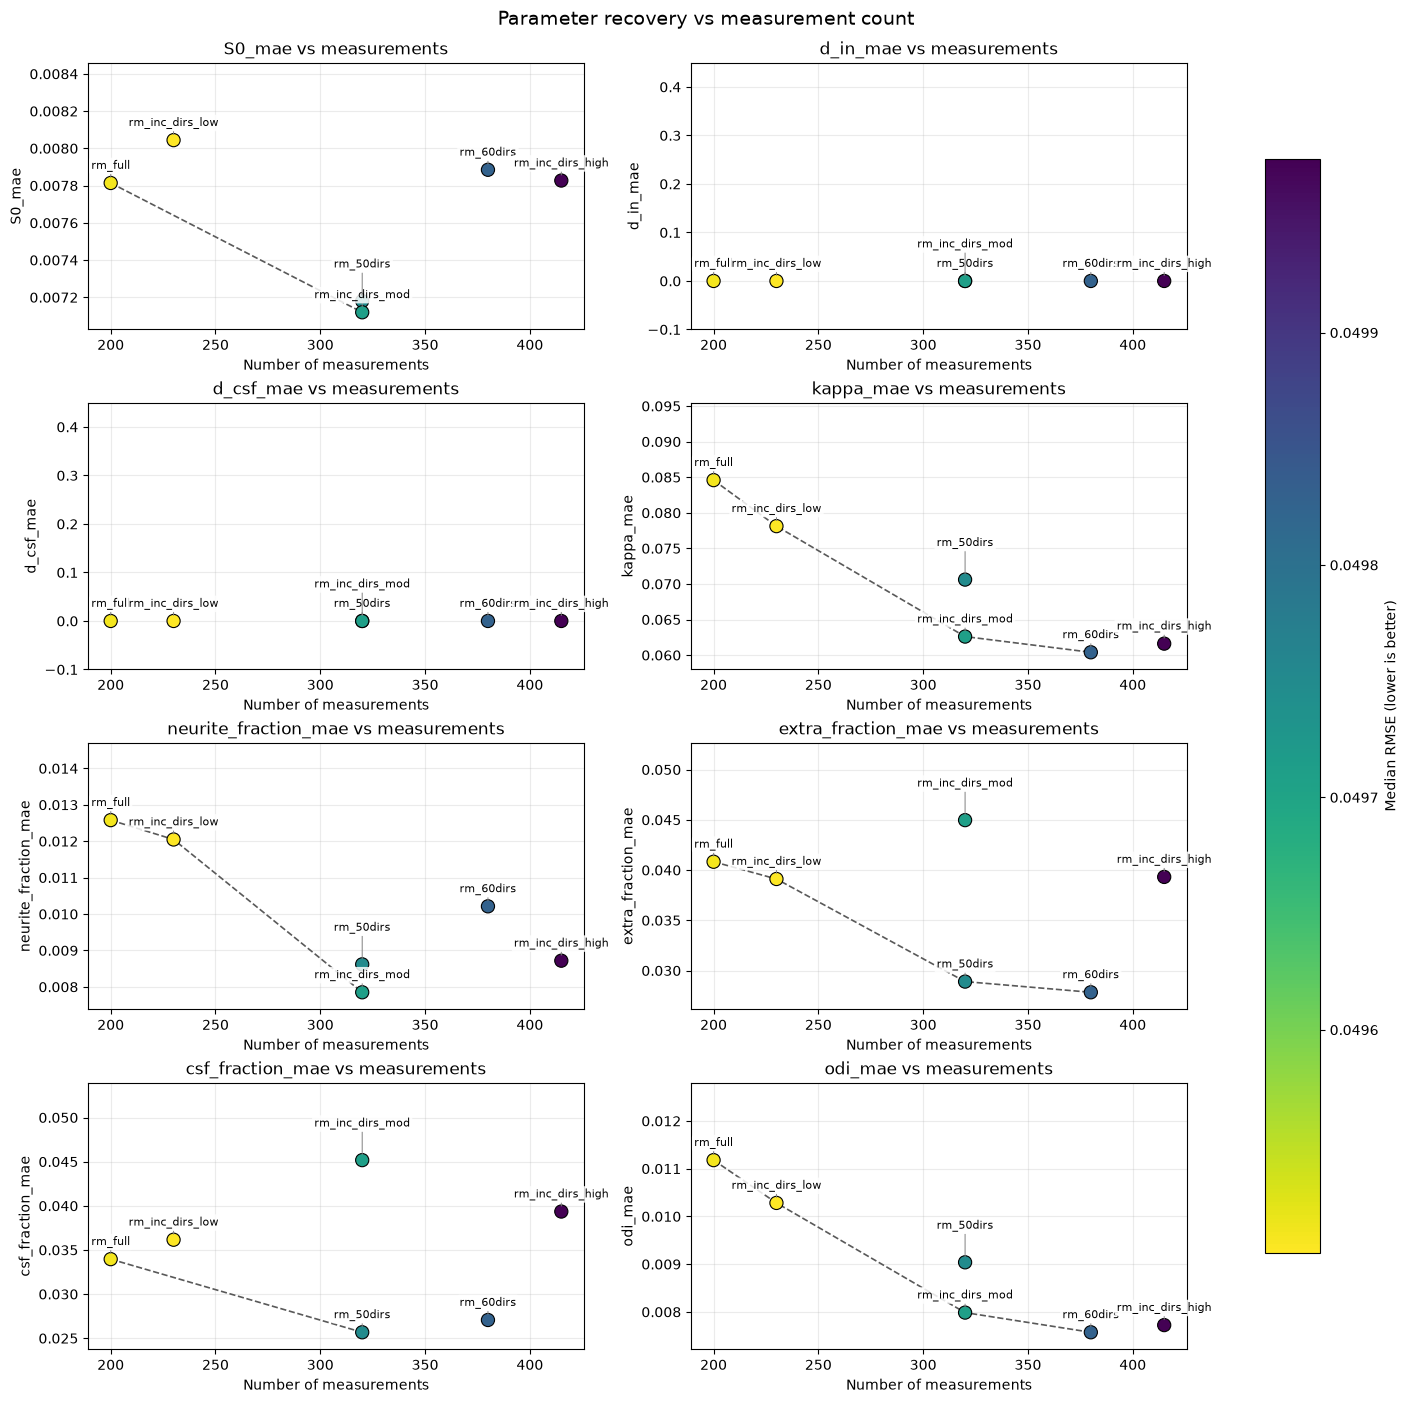

In [50]:
# -----------------------------------------------------------------------------
# Build a per-acquisition table of parameter MAEs
# -----------------------------------------------------------------------------
mae_map = {
    "S0_mae": "S0_error",
    "d_in_mae": "d_in_error",
    "d_csf_mae": "d_csf_error",
    "kappa_mae": "kappa_error",
    "neurite_fraction_mae": "neurite_fraction_error",
    "extra_fraction_mae": "extra_fraction_error",
    "csf_fraction_mae": "csf_fraction_error",
    "odi_mae": "odi_error",
}

per_acq = (
    df.groupby("acquisition")
    .agg(
        success_rate=("success", "mean"),
        n_measurements=("n_measurements", "first"),
        n_evaluations_median=("n_evaluations", "median"),
        rmse_median=("rmse", "median"),
        nrmse_median=("nrmse", "median"),
        S0_mae=("S0_error", lambda x: np.nanmean(np.abs(x))),
        d_in_mae=("d_in_error", lambda x: np.nanmean(np.abs(x))),
        d_csf_mae=("d_csf_error", lambda x: np.nanmean(np.abs(x))),
        kappa_mae=("kappa_error", lambda x: np.nanmean(np.abs(x))),
        neurite_fraction_mae=("neurite_fraction_error", lambda x: np.nanmean(np.abs(x))),
        extra_fraction_mae=("extra_fraction_error", lambda x: np.nanmean(np.abs(x))),
        csf_fraction_mae=("csf_fraction_error", lambda x: np.nanmean(np.abs(x))),
        odi_mae=("odi_error", lambda x: np.nanmean(np.abs(x))),
    )
    .reset_index()
)

# Keep all acquisitions for tables, but only plot the ones we want.
plot_per_acq = per_acq[
    per_acq["acquisition"] != "uk_biobank"
].copy()

# -----------------------------------------------------------------------------
# Optional: identify a simple Pareto frontier for each metric
# (lower n_measurements and lower MAE are both better)
# -----------------------------------------------------------------------------
def pareto_mask(x: np.ndarray, y: np.ndarray) -> np.ndarray:
    """
    Returns a boolean mask for non-dominated points.
    Lower x and lower y are better.
    """
    n = len(x)
    mask = np.ones(n, dtype=bool)
    for i in range(n):
        if not mask[i]:
            continue
        dominated = (x <= x[i]) & (y <= y[i]) & ((x < x[i]) | (y < y[i]))
        if np.any(dominated):
            mask[i] = False
    return mask


def plot_metric_vs_measurements(
    ax,
    table,
    metric,
    title=None,
    label_step=14,   # vertical spacing between labels, in points
    base_offset=8,   # starting offset above the point, in points
):
    x = table["n_measurements"].to_numpy()
    y = table[metric].to_numpy()
    c = table["rmse_median"].to_numpy()

    norm = Normalize(
        vmin=table["rmse_median"].min(),
        vmax=table["rmse_median"].max(),
    )

    sc = ax.scatter(
        x,
        y,
        c=c,
        cmap="viridis_r",
        norm=norm,
        s=90,
        edgecolor="black",
        linewidth=0.8,
        zorder=3,
    )

    # Give the axis a bit of headroom for stacked labels.
    y_min = np.nanmin(y)
    y_max = np.nanmax(y)
    y_span = y_max - y_min if y_max > y_min else 1.0
    ax.set_ylim(y_min - 0.10 * y_span, y_max + 0.45 * y_span)

    # Sort so within each x-group, the best metric value gets the closest label.
    plot_table = table.sort_values(
        ["n_measurements", metric, "acquisition"],
        ascending=[True, True, True],
    ).copy()

    # One vertical stack per x-value.
    for xval, grp in plot_table.groupby("n_measurements", sort=True):
        grp = grp.sort_values(metric, ascending=True).reset_index(drop=True)

        for j, row in grp.iterrows():
            ax.annotate(
                row["acquisition"],
                xy=(row["n_measurements"], row[metric]),
                xytext=(0, base_offset + label_step * j),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8,
                bbox=dict(
                    boxstyle="round,pad=0.2",
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.85,
                ),
                arrowprops=dict(
                    arrowstyle="-",
                    color="0.5",
                    lw=0.7,
                    shrinkA=0,
                    shrinkB=4,
                ),
                zorder=4,
            )

    # Pareto frontier line
    pmask = pareto_mask(x, y)
    pareto = table.loc[pmask].sort_values("n_measurements")
    ax.plot(
        pareto["n_measurements"],
        pareto[metric],
        linestyle="--",
        linewidth=1.2,
        color="0.35",
        zorder=2,
    )

    ax.set_xlabel("Number of measurements")
    ax.set_ylabel(metric)
    ax.set_title(title or metric)
    ax.grid(True, alpha=0.25)

    return sc

# -----------------------------------------------------------------------------
# Make one subplot per metric
# -----------------------------------------------------------------------------
metrics = list(mae_map.keys())

ncols = 2
nrows = int(np.ceil(len(metrics) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(14, 3.4 * nrows),
    constrained_layout=True,
)

axes = np.array(axes).reshape(-1)

last_sc = None
for ax, metric in zip(axes, metrics):
    last_sc = plot_metric_vs_measurements(
        ax=ax,
        table=plot_per_acq,
        metric=metric,
        title=f"{metric} vs measurements",
    )

for ax in axes[len(metrics):]:
    ax.axis("off")

cbar = fig.colorbar(last_sc, ax=axes.tolist(), shrink=0.85)
cbar.set_label("Median RMSE (lower is better)")

fig.suptitle("Parameter recovery vs measurement count", y=1.02, fontsize=14)
plt.show()